# DEEP LEARNING LAB MANUAL
## CO3 – Recurrent Neural Networks (RNN)

**Name:** Harigowtham. A  
**Register Number:** 192324198  
**Course Code:** CSA4708  
**Course Name:** Deep Learning  
**Platform:** Google Colab

### Instructions
Run cells from top to bottom. This manual follows the seven experiments in the supplied CO3 RNN question sheet. The datasets and sample values below are those provided in the question sheet. Neural-network outputs may vary slightly because training is stochastic.

## Common setup
Import the required Python libraries and set random seeds.

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
np.random.seed(42)
tf.random.set_seed(42)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


# Experiment 1 – Basic RNN for Sequential Data Processing
**Scenario:** Student Activity Monitoring System

**Aim:** Process four consecutive days of study hours (2, 3, 4, 5) using a SimpleRNN layer and a Dense output layer. Display the model summary and predicted output.

In [2]:
X = np.array([[[2.0], [3.0], [4.0], [5.0]]], dtype=np.float32)
model = keras.Sequential([
    layers.Input(shape=(4, 1)),
    layers.SimpleRNN(8, activation="tanh"),
    layers.Dense(1)
])
model.compile(optimizer="adam", loss="mse")
model.summary()
prediction = model.predict(X, verbose=0)
print("Input study-hour sequence:", X.reshape(-1))
print("Predicted output:", prediction[0, 0])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 8)              │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89 (356.00 B)

 Trainable params: 89 (356.00 B)

 Non-trainable params: 0 (0.00 B)

Input study-hour sequence: [2. 3. 4. 5.]
Predicted output: -0.17504765


**Result:** A basic RNN was implemented using SimpleRNN and Dense layers. The model summary and predicted output are displayed. The question supplies no target output, so this experiment demonstrates sequence processing and prediction rather than supervised training.

# Experiment 2 – Next Value Prediction in a Numerical Sequence
**Scenario:** Smart Number Pattern Prediction System

**Aim:** Learn the relationship between the previous three values and the next value, then predict the next value for **60, 70, 80**.

**Given pairs:** 10,20,30→40; 20,30,40→50; 30,40,50→60; 40,50,60→70; 50,60,70→80.

Input sequence: 60, 70, 80
Predicted next value: 87.66
Expected pattern value: 90


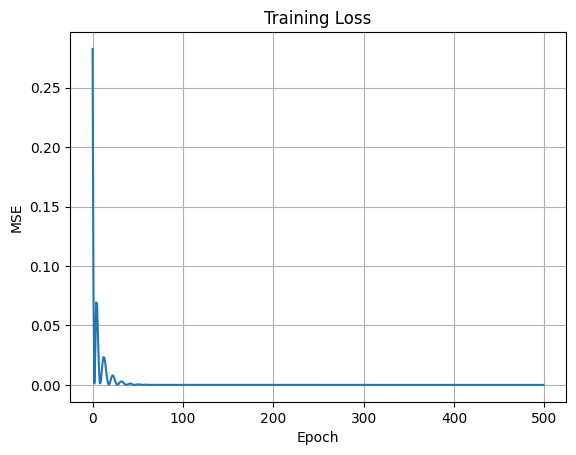

In [3]:
X = np.array([[10,20,30],[20,30,40],[30,40,50],[40,50,60],[50,60,70]], dtype=np.float32)
y = np.array([40,50,60,70,80], dtype=np.float32)
Xr = (X/100.0).reshape(-1,3,1)
ys = y/100.0
model = keras.Sequential([layers.Input((3,1)), layers.SimpleRNN(16), layers.Dense(1)])
model.compile(optimizer=keras.optimizers.Adam(0.01), loss="mse")
history = model.fit(Xr, ys, epochs=500, verbose=0)
test = np.array([60,70,80], dtype=np.float32).reshape(1,3,1)/100
pred = model.predict(test, verbose=0)[0,0]*100
print("Input sequence: 60, 70, 80")
print("Predicted next value:", round(float(pred),2))
print("Expected pattern value: 90")
plt.plot(history.history["loss"]); plt.title("Training Loss"); plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.grid(); plt.show()

**Result:** The RNN was trained using the five given sequences and used to predict the next value for 60, 70, 80. The expected pattern continuation is **90**. The model prediction is printed above and may be approximate because the dataset is very small.

# Experiment 3 – RNN for Text Sentiment Classification
**Scenario:** Online Product Review Analysis

**Aim:** Convert reviews into numerical sequences using Tokenizer and padding. Train an Embedding + SimpleRNN sentiment classifier and classify a new review.

**Given reviews:** “I love this product” (Positive), “Excellent quality” (Positive), “Very useful product” (Positive), “I hate this product” (Negative), “Very poor quality” (Negative), “Product is terrible” (Negative).

Word index: {'<OOV>': 1, 'product': 2, 'i': 3, 'this': 4, 'quality': 5, 'very': 6, 'love': 7, 'excellent': 8, 'useful': 9, 'hate': 10, 'poor': 11, 'is': 12, 'terrible': 13}
Padded sequences:
 [[ 3  7  4  2]
 [ 8  5  0  0]
 [ 6  9  2  0]
 [ 3 10  4  2]
 [ 6 11  5  0]
 [ 2 12 13  0]]
New review: I love this product
Positive probability: 0.9479
Predicted sentiment: Positive


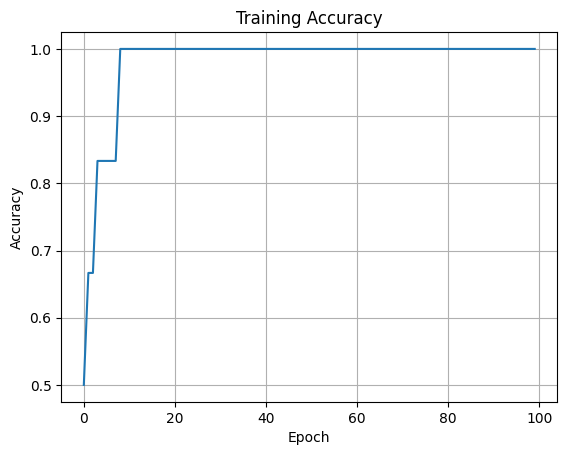

In [4]:
reviews = ["I love this product","Excellent quality","Very useful product",
           "I hate this product","Very poor quality","Product is terrible"]
labels = np.array([1,1,1,0,0,0], dtype=np.float32)  # 1=Positive, 0=Negative
tokenizer = Tokenizer(oov_token="<OOV>")
tokenizer.fit_on_texts(reviews)
seq = tokenizer.texts_to_sequences(reviews)
max_len = max(map(len, seq))
X = pad_sequences(seq, maxlen=max_len, padding="post")
print("Word index:", tokenizer.word_index)
print("Padded sequences:\n", X)
model = keras.Sequential([
    layers.Input((max_len,)),
    layers.Embedding(len(tokenizer.word_index)+1, 8),
    layers.SimpleRNN(16),
    layers.Dense(1, activation="sigmoid")
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
h = model.fit(X, labels, epochs=100, verbose=0)
new_review = ["I love this product"]
new_X = pad_sequences(tokenizer.texts_to_sequences(new_review), maxlen=max_len, padding="post")
p = float(model.predict(new_X, verbose=0)[0,0])
print("New review:", new_review[0])
print("Positive probability:", round(p,4))
print("Predicted sentiment:", "Positive" if p >= 0.5 else "Negative")
plt.plot(h.history["accuracy"]); plt.title("Training Accuracy"); plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.grid(); plt.show()

**Result:** The reviews were tokenized, padded and processed by an RNN sentiment classifier. The model classifies a new review as positive or negative. This six-review dataset is only for laboratory demonstration and is not sufficient for reliable real-world sentiment analysis.

# Experiment 4 – Character-Level Text Generation Using RNN
**Scenario:** Automatic Text Completion System

**Aim:** Use the training text `machine learning is interesting`, encode characters, create sequences from the previous four characters, train a SimpleRNN and generate additional characters.

In [5]:
text_data = "machine learning is interesting"
chars = sorted(set(text_data))
char_to_id = {ch:i for i,ch in enumerate(chars)}
id_to_char = {i:ch for ch,i in char_to_id.items()}
print("Character mapping:", char_to_id)
seq_len = 4
X, y = [], []
for i in range(len(text_data)-seq_len):
    X.append([char_to_id[ch] for ch in text_data[i:i+seq_len]])
    y.append(char_to_id[text_data[i+seq_len]])
X, y = np.array(X), np.array(y)
model = keras.Sequential([
    layers.Input((seq_len,)),
    layers.Embedding(len(chars), 16),
    layers.SimpleRNN(64),
    layers.Dense(len(chars), activation="softmax")
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
model.fit(X, y, epochs=300, verbose=0)
def generate(seed, count=20):
    result = seed
    for _ in range(count):
        encoded = [char_to_id[ch] for ch in result[-seq_len:]]
        probs = model.predict(np.array(encoded).reshape(1,seq_len), verbose=0)[0]
        result += id_to_char[int(np.argmax(probs))]
    return result
seed = "mach"
print("Starting sequence:", seed)
print("Generated text:", generate(seed, 20))

Character mapping: {' ': 0, 'a': 1, 'c': 2, 'e': 3, 'g': 4, 'h': 5, 'i': 6, 'l': 7, 'm': 8, 'n': 9, 'r': 10, 's': 11, 't': 12}
Starting sequence: mach
Generated text: machine learning is inte


**Result:** A character-level RNN was trained to predict the next character from the previous four characters. Additional characters were generated from `mach`. Because the training text is short, the generated text may not form meaningful sentences.

# Experiment 5 – RNN for Time-Series Forecasting
**Scenario:** Monthly Sales Prediction System

**Aim:** Use the previous three months' sales to predict the next month and forecast the month after December.

**Given sales:** January–December = 100, 110, 120, 130, 140, 150, 160, 170, 180, 190, 200, 210.

Previous months (Oct, Nov, Dec): 190, 200, 210
Forecast for next January: 215.28
Expected continuation: 220


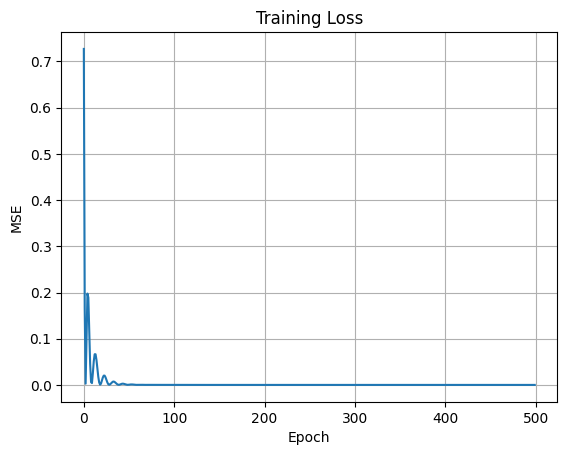

In [6]:
sales = np.array([100,110,120,130,140,150,160,170,180,190,200,210], dtype=np.float32)
X, y = [], []
for i in range(len(sales)-3):
    X.append(sales[i:i+3]); y.append(sales[i+3])
X, y = np.array(X), np.array(y)
Xr, ys = (X/250).reshape(-1,3,1), y/250
model = keras.Sequential([layers.Input((3,1)), layers.SimpleRNN(16), layers.Dense(1)])
model.compile(optimizer=keras.optimizers.Adam(0.01), loss="mse")
h = model.fit(Xr, ys, epochs=500, verbose=0)
last = np.array([190,200,210], dtype=np.float32).reshape(1,3,1)/250
forecast = float(model.predict(last, verbose=0)[0,0]*250)
print("Previous months (Oct, Nov, Dec): 190, 200, 210")
print("Forecast for next January:", round(forecast,2))
print("Expected continuation: 220")
plt.plot(h.history["loss"]); plt.title("Training Loss"); plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.grid(); plt.show()

**Result:** The RNN used three-month sliding windows to forecast the next month's sales. The expected continuation is **220**. The model output is displayed above and may be approximate because only twelve observations are supplied.

# Experiment 6 – Daily Electricity Consumption Prediction Using RNN
**Scenario:** Smart Electricity Management System

**Aim:** Use the previous three days' electricity consumption to estimate Day 13.

**Given consumption (units):** Day 1–12 = 100, 115, 120, 130, 145, 150, 165, 170, 185, 190, 205, 215.

Input (Days 10–12): 190, 205, 215
Predicted Day 13 consumption: 218.19 units


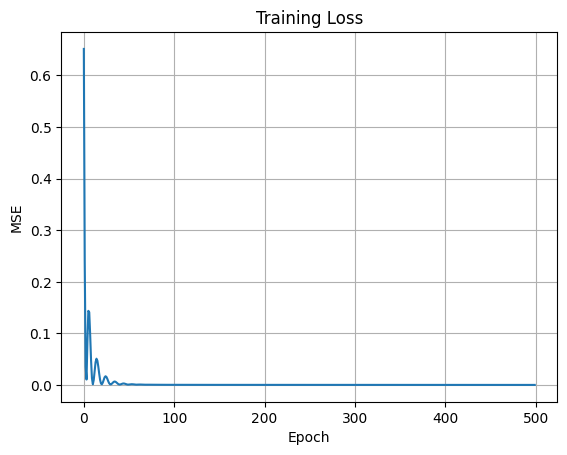

In [7]:
values = np.array([100,115,120,130,145,150,165,170,185,190,205,215], dtype=np.float32)
X, y = [], []
for i in range(len(values)-3):
    X.append(values[i:i+3]); y.append(values[i+3])
X, y = np.array(X), np.array(y)
Xr, ys = (X/250).reshape(-1,3,1), y/250
model = keras.Sequential([layers.Input((3,1)), layers.SimpleRNN(16), layers.Dense(1)])
model.compile(optimizer=keras.optimizers.Adam(0.01), loss="mse")
h = model.fit(Xr, ys, epochs=500, verbose=0)
last = np.array([190,205,215], dtype=np.float32).reshape(1,3,1)/250
day13 = float(model.predict(last, verbose=0)[0,0]*250)
print("Input (Days 10–12): 190, 205, 215")
print("Predicted Day 13 consumption:", round(day13,2), "units")
plt.plot(h.history["loss"]); plt.title("Training Loss"); plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.grid(); plt.show()

**Result:** An RNN-based electricity consumption model was trained using the given daily values. It estimates Day 13 consumption using Days 10, 11 and 12 as input. The prediction is displayed in units.

# Experiment 7 – Next-Word Prediction Using RNN
**Scenario:** Intelligent Sentence Completion Application

**Aim:** Tokenize and pad the training sentences, train Embedding and SimpleRNN layers, and predict the next word for **“I love”**.

**Given sentences:** “I love machine learning”, “I love deep learning”, “I love artificial intelligence”, “I like machine learning”, “I like deep learning”.

Word index: {'<OOV>': 1, 'i': 2, 'learning': 3, 'love': 4, 'machine': 5, 'deep': 6, 'like': 7, 'artificial': 8, 'intelligence': 9}
Padded sequences:
 [[0 0 2 4]
 [0 2 4 5]
 [2 4 5 3]
 [0 0 2 4]
 [0 2 4 6]
 [2 4 6 3]
 [0 0 2 4]
 [0 2 4 8]
 [2 4 8 9]
 [0 0 2 7]
 [0 2 7 5]
 [2 7 5 3]
 [0 0 2 7]
 [0 2 7 6]
 [2 7 6 3]]
Input phrase: I love
Predicted next word: machine


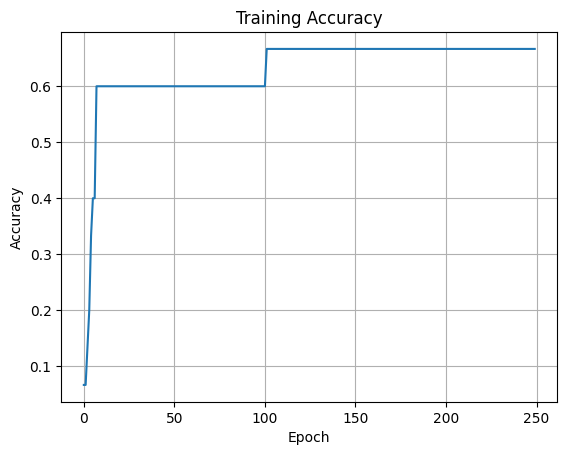

In [8]:
sentences = [
    "I love machine learning",
    "I love deep learning",
    "I love artificial intelligence",
    "I like machine learning",
    "I like deep learning"
]
tokenizer = Tokenizer(oov_token="<OOV>")
tokenizer.fit_on_texts(sentences)
word_seqs = tokenizer.texts_to_sequences(sentences)
training_seqs = []
for seq in word_seqs:
    for i in range(1, len(seq)):
        training_seqs.append(seq[:i+1])
max_len = max(map(len, training_seqs))
training_seqs = pad_sequences(training_seqs, maxlen=max_len, padding="pre")
X, y = training_seqs[:,:-1], training_seqs[:,-1]
vocab_size = len(tokenizer.word_index)+1
print("Word index:", tokenizer.word_index)
print("Padded sequences:\n", training_seqs)
model = keras.Sequential([
    layers.Input((max_len-1,)),
    layers.Embedding(vocab_size, 16),
    layers.SimpleRNN(32),
    layers.Dense(vocab_size, activation="softmax")
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h = model.fit(X, y, epochs=250, verbose=0)
seed = "I love"
seed_seq = tokenizer.texts_to_sequences([seed])[0]
seed_pad = pad_sequences([seed_seq], maxlen=max_len-1, padding="pre")
probs = model.predict(seed_pad, verbose=0)[0]
idx = int(np.argmax(probs))
id_to_word = {i:w for w,i in tokenizer.word_index.items()}
print("Input phrase:", seed)
print("Predicted next word:", id_to_word.get(idx, "<unknown>"))
plt.plot(h.history["accuracy"]); plt.title("Training Accuracy"); plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.grid(); plt.show()

**Result:** The next-word prediction system was implemented using Tokenizer, padding, Embedding and SimpleRNN layers. The model predicts a likely next word after `I love`. The supplied examples contain multiple valid continuations (`machine`, `deep`, and `artificial`), so the selected word depends on the learned probabilities.

# Overall Conclusion

The seven CO3 experiments were implemented in Google Colab using Python and TensorFlow/Keras. They demonstrate basic sequential processing, numerical sequence prediction, sentiment classification, character-level text generation, time-series forecasting, electricity consumption prediction and next-word prediction.

**End of CO3 – RNN Lab Manual**